In [1]:
# Analisi statistica del meteo

# Importiamo le librerie per test statistici e visualizzazioni.
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, kruskal
from pathlib import Path

MUTED = '#647280'
NEUTRAL = '#86939E'
DIVERGING_CMAP = 'BrBG'
plt.rcParams['figure.facecolor'] = '#F8F8F8'
plt.rcParams['axes.facecolor'] = '#F8F8F8'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

OUT=Path('../output/figures');OUT.mkdir(parents=True,exist_ok=True)

# Apriamo i dati giornalieri, senza trattare le 24 ore come repliche indipendenti.
day=pd.read_csv('../data/processed/bike_day_clean.csv',parse_dates=['dteday'])
day['year']=day['dteday'].dt.year
day['month']=day['dteday'].dt.month
day['temperature_c']=day['temp']*41

# Consideriamo le tre categorie meteo con osservazioni sufficienti.
weather_names={1:'Clear',2:'Mist / cloudy',3:'Light rain / snow'}
valid=day[day['weathersit'].isin(weather_names)].copy()
valid['weather']=valid['weathersit'].map(weather_names)

# Calcoliamo la mediana di ogni mese/anno come riferimento.
valid['month_reference']=(valid.groupby(['year','month'])['cnt'].transform('median'))

# Esprimiamo la domanda come rapporto rispetto al mese di appartenenza.
valid['relative_demand']=valid['cnt']/valid['month_reference']
print('Daily observations by weather:')
print(valid['weather'].value_counts())

Daily observations by weather:
weather
Clear                463
Mist / cloudy        247
Light rain / snow     21
Name: count, dtype: int64


Kruskal–Wallis H=126.89; p=2.79e-28; epsilon squared (approx.)=0.172
Median ratio to same-month reference:
weather
Clear                1.030
Mist / cloudy        0.905
Light rain / snow    0.443
Name: relative_demand, dtype: float64


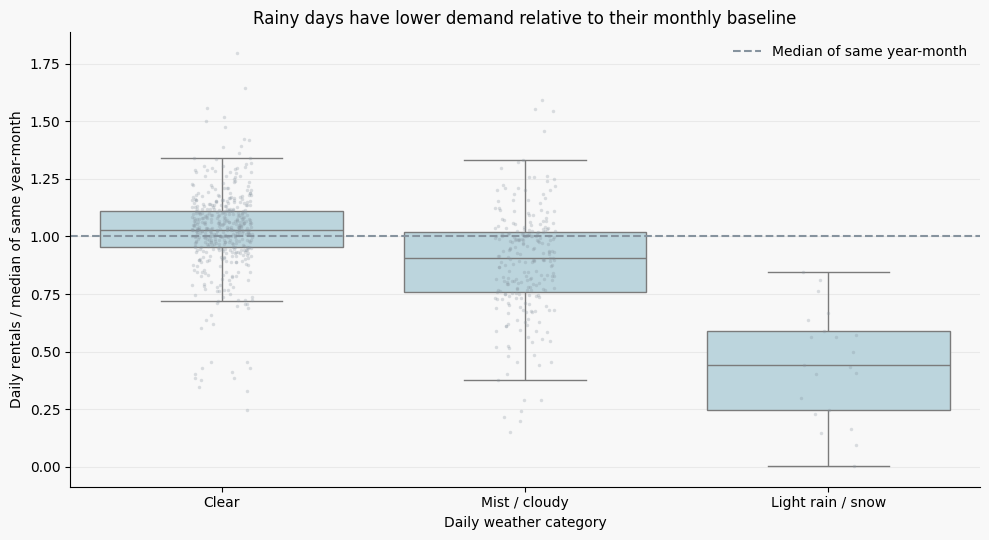

In [2]:
# Ordiniamo le categorie del meteo e prepariamo le distribuzioni.
order=list(weather_names.values())
series=[valid.loc[valid['weather']==name,'relative_demand'] for name in order]

# Usiamo Kruskal–Wallis per confrontare gruppi senza assumere normalità.
H,p=kruskal(*series)
n=len(valid);k=len(series)

# Calcoliamo anche ε² per valutare l’ampiezza della differenza.
epsilon2=max(0,(H-k+1)/(n-k))
print(f'Kruskal–Wallis H={H:.2f}; p={p:.3g}; epsilon squared (approx.)={epsilon2:.3f}')
print('Median ratio to same-month reference:')
print(valid.groupby('weather')['relative_demand'].median().reindex(order).round(3))

# Mostriamo le distribuzioni con box plot e punti.
fig,ax=plt.subplots(figsize=(10,5.5))
sns.boxplot(data=valid,x='weather',y='relative_demand',order=order,
            color='#B6D8E3',showfliers=False,ax=ax)
sns.stripplot(data=valid,x='weather',y='relative_demand',order=order,
              color=NEUTRAL,alpha=.28,size=2.5,ax=ax)

# Indichiamo con una linea il riferimento mensile, pari a 1.
ax.axhline(1,ls='--',color=NEUTRAL,label='Median of same year-month')
ax.set(title='Rainy days have lower demand relative to their monthly baseline',
       xlabel='Daily weather category',ylabel='Daily rentals / median of same year-month')
ax.grid(axis='y', alpha=0.2); ax.set_axisbelow(True);ax.legend(frameon=False)
fig.tight_layout();fig.savefig(OUT/'RQ9A_weather_statistical.png',dpi=200,bbox_inches='tight');plt.show()

,year,variable,rho,p
0,2011,temperature_c,0.7623,0.0000
1,2011,hum,-0.0195,0.7107
2,2011,windspeed,-0.2579,0.0000
3,2012,temperature_c,0.7001,0.0000
4,2012,hum,-0.0547,0.2970
5,2012,windspeed,-0.2474,0.0000


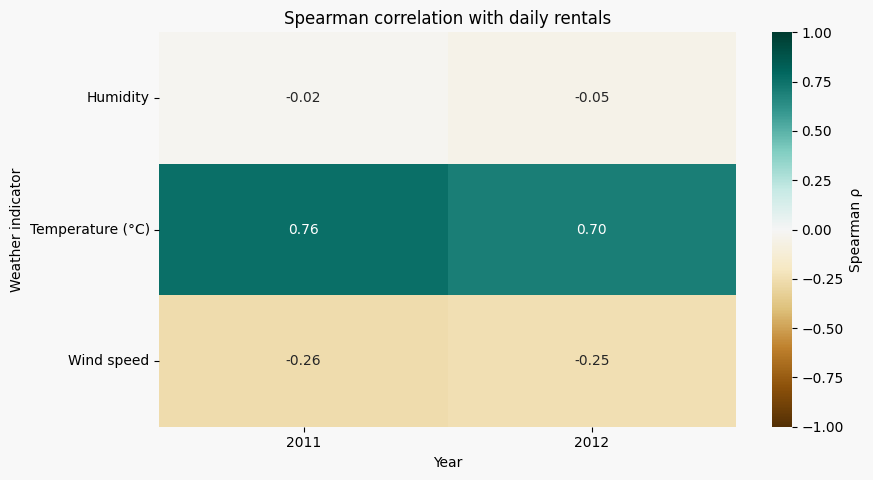

In [3]:
# Calcoliamo le correlazioni di Spearman separatamente per anno.
rows=[]

# Analizziamo temperatura, umidità e vento rispetto ai noleggi.
for year,grp in day.groupby('year'):
    for variable in ['temperature_c','hum','windspeed']:
        rho,pv=spearmanr(grp[variable],grp['cnt'])
        rows.append({'year':year,'variable':variable,'rho':rho,'p':pv})

# Organizziamo i risultati in una tabella.
corr_df=pd.DataFrame(rows)
display(corr_df.round(4))

# Mostriamo le correlazioni con una heatmap centrata sullo zero.
fig,ax=plt.subplots(figsize=(9,4.9))
pivot=corr_df.pivot(index='variable',columns='year',values='rho')
# Rinominiamo gli indicatori soltanto per la lettura della figura.
pivot = pivot.rename(index={'temperature_c':'Temperature (°C)',
                            'hum':'Humidity', 'windspeed':'Wind speed'})
sns.heatmap(pivot,annot=True,fmt='.2f',cmap=DIVERGING_CMAP,center=0,vmin=-1,vmax=1,ax=ax,
            cbar_kws={'label':'Spearman ρ'})
ax.set(title='Spearman correlation with daily rentals',
       xlabel='Year',ylabel='Weather indicator')
ax.tick_params(axis='both',rotation=0)
fig.tight_layout();fig.savefig(OUT/'RQ9B_spearman_by_year.png',dpi=200,bbox_inches='tight');plt.show()